In [7]:
from google.colab import files
uploaded = files.upload()

Saving retail_sales_dataset.csv to retail_sales_dataset (2).csv


In [8]:
print(uploaded.keys())

dict_keys(['retail_sales_dataset (2).csv'])


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("retail_sales_dataset (2).csv")
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())

Dataset loaded successfully!
Dataset shape: (1000, 9)

First 5 rows:


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100



Column names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']


In [10]:
# Dataset information
print("Dataset Information:")
df.info()
# Number of rows and columns
print("\nRows and Columns:")
print(df.shape)
# Column names
print("\nColumn Names:")
print(df.columns.tolist())
# Data types
print("\nData Types:")
print(df.dtypes)
# Missing values
print("\nMissing Values:")
print(df.isnull().sum())
# Duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB

Rows and Columns:
(1000, 9)

Column Names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Data Types:
Transaction ID       int64
Date                object
Customer ID         object
Gender              object
Age                  int64


In [11]:
print("Descriptive Statistics:")
display(df.describe(include="all"))

Descriptive Statistics:


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
count,1000.000000,1000,1000,1000,1000.00000,1000,1000.000000,1000.000000,1000.000000
unique,NaN,345,1000,2,NaN,3,NaN,NaN,NaN
top,NaN,2023-05-16,CUST1000,Female,NaN,Clothing,NaN,NaN,NaN
freq,NaN,11,1,510,NaN,351,NaN,NaN,NaN
mean,500.500000,NaN,NaN,NaN,41.39200,NaN,2.514000,179.890000,456.000000
std,288.819436,NaN,NaN,NaN,13.68143,NaN,1.132734,189.681356,559.997632
min,1.000000,NaN,NaN,NaN,18.00000,NaN,1.000000,25.000000,25.000000
25%,250.750000,NaN,NaN,NaN,29.00000,NaN,1.000000,30.000000,60.000000
50%,500.500000,NaN,NaN,NaN,42.00000,NaN,3.000000,50.000000,135.000000
75%,750.250000,NaN,NaN,NaN,53.00000,NaN,4.000000,300.000000,900.000000


In [12]:
print("Numerical Summary:")
display(df.describe())
print("\nCategorical Summary:")
display(df.describe(include="object"))

Numerical Summary:


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000



Categorical Summary:


,Date,Customer ID,Gender,Product Category
count,1000,1000,1000,1000
unique,345,1000,2,3
top,2023-05-16,CUST1000,Female,Clothing
freq,11,1,510,351


In [13]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
print(df.dtypes)
print("\nInvalid dates:", df["Date"].isna().sum())

Transaction ID               int64
Date                datetime64[ns]
Customer ID                 object
Gender                      object
Age                          int64
Product Category            object
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object

Invalid dates: 0


Transactions by Product Category:


,count
Product Category,
Clothing,351
Electronics,342
Beauty,307


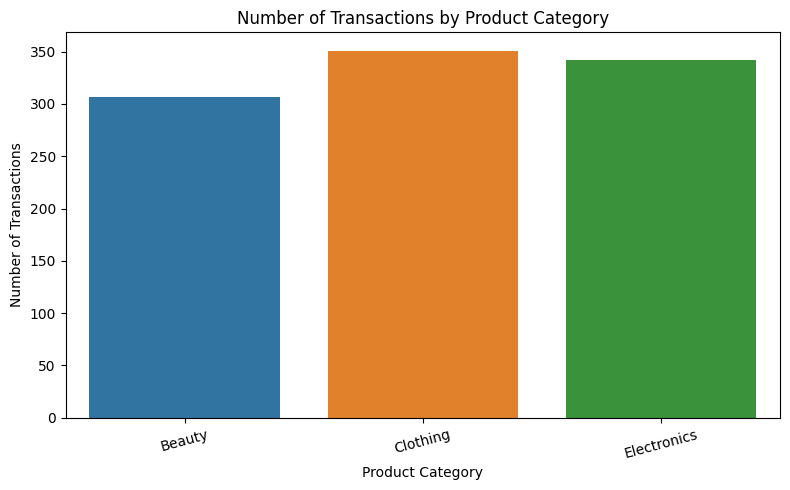

In [14]:
# Count transactions by product category
category_counts = df["Product Category"].value_counts()
print("Transactions by Product Category:")
display(category_counts)
# Visualize product categories
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Product Category", hue="Product Category", legend=False)
plt.title("Number of Transactions by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

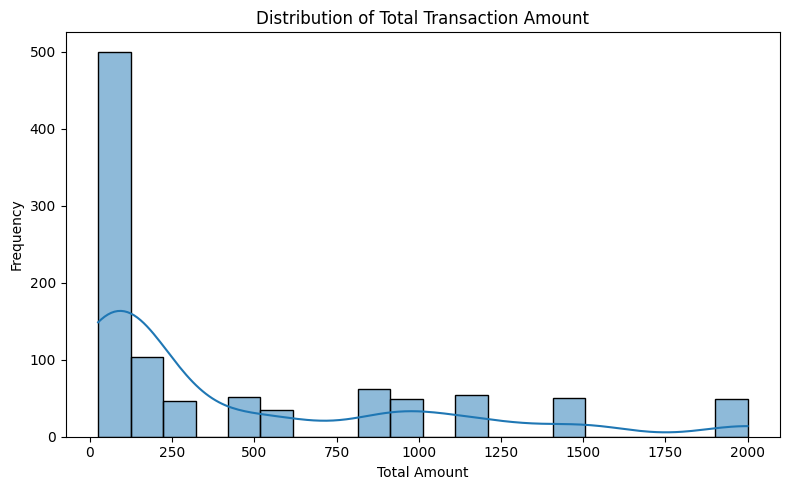

In [15]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Total Amount", bins=20, kde=True)
plt.title("Distribution of Total Transaction Amount")
plt.xlabel("Total Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

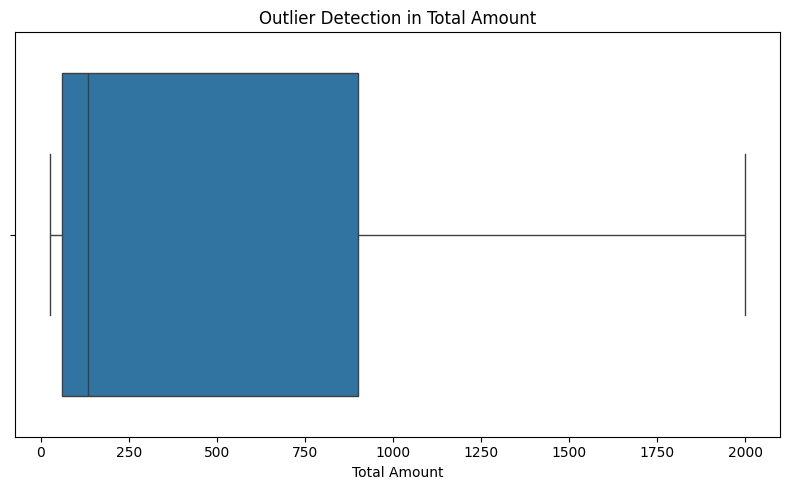

In [16]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Total Amount")
plt.title("Outlier Detection in Total Amount")
plt.xlabel("Total Amount")
plt.tight_layout()
plt.show()

Total Sales by Gender:


,Total Amount
Gender,
Female,232840
Male,223160


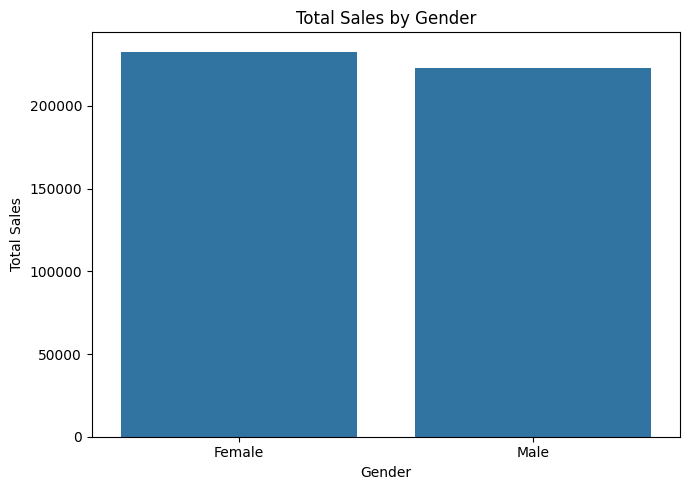

In [17]:
# Gender-wise total sales
gender_sales = df.groupby("Gender")["Total Amount"].sum()
print("Total Sales by Gender:")
display(gender_sales)
# Bar chart
plt.figure(figsize=(7, 5))
sns.barplot(
    x=gender_sales.index,
    y=gender_sales.values
)
plt.title("Total Sales by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

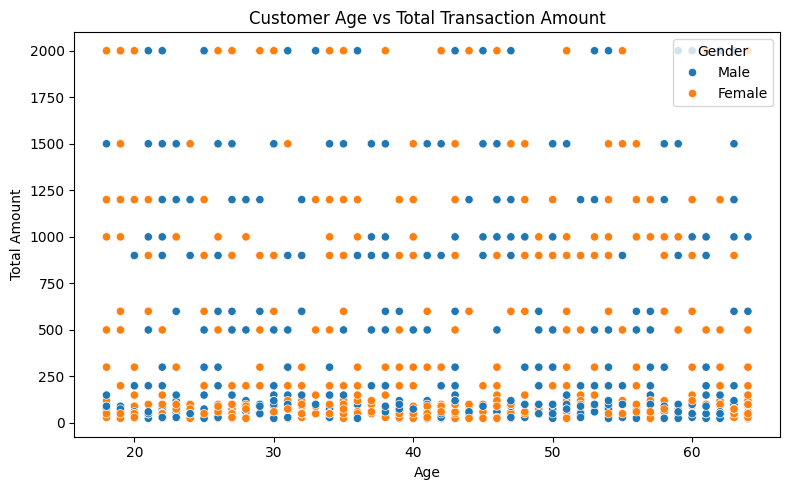

In [18]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Age",
    y="Total Amount",
    hue="Gender"
)
plt.title("Customer Age vs Total Transaction Amount")
plt.xlabel("Age")
plt.ylabel("Total Amount")
plt.tight_layout()
plt.show()

Correlation Matrix:


,Age,Quantity,Price per Unit,Total Amount
Age,1.000000,-0.023737,-0.038423,-0.060568
Quantity,-0.023737,1.000000,0.017501,0.373707
Price per Unit,-0.038423,0.017501,1.000000,0.851925
Total Amount,-0.060568,0.373707,0.851925,1.000000


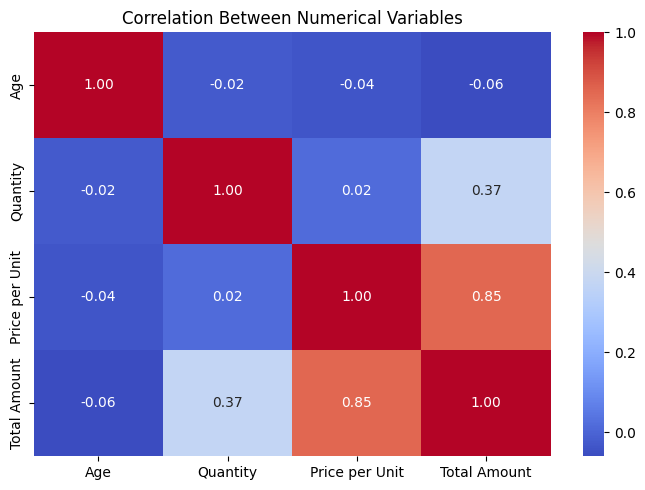

In [19]:
numeric_df = df[
    ["Age", "Quantity", "Price per Unit", "Total Amount"]
]
correlation = numeric_df.corr()
print("Correlation Matrix:")
display(correlation)
plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.show()

In [20]:
print("EDA KEY FINDINGS")
print("-" * 35)
print("Total Transactions:", len(df))
print("Total Revenue:", df["Total Amount"].sum())
print("Average Transaction Value:", round(df["Total Amount"].mean(), 2))
print("Average Customer Age:", round(df["Age"].mean(), 2))
print("\nTop Product Category:")
print(df["Product Category"].value_counts().idxmax())
print("\nSales by Product Category:")
display(
    df.groupby("Product Category")["Total Amount"]
      .agg(["sum", "mean", "count"])
      .sort_values("sum", ascending=False)
)

EDA KEY FINDINGS
-----------------------------------
Total Transactions: 1000
Total Revenue: 456000
Average Transaction Value: 456.0
Average Customer Age: 41.39

Top Product Category:
Clothing

Sales by Product Category:


,sum,mean,count
Product Category,,,
Electronics,156905,458.786550,342
Clothing,155580,443.247863,351
Beauty,143515,467.475570,307


In [21]:
# Generate EDA Summary Report
total_transactions = len(df)
total_revenue = df["Total Amount"].sum()
avg_transaction = df["Total Amount"].mean()
avg_age = df["Age"].mean()
top_category = df["Product Category"].value_counts().idxmax()
top_gender = df["Gender"].value_counts().idxmax()
report = f"""
CODSOFT DATA SCIENCE INTERNSHIP
TASK 2: EXPLORATORY DATA ANALYSIS
1. Dataset Overview
- Total transactions: {total_transactions}
- Total columns: {df.shape[1]}
- Missing values: {df.isnull().sum().sum()}
- Duplicate records: {df.duplicated().sum()}
2. Descriptive Statistics
- Average customer age: {avg_age:.2f}
- Average transaction amount: {avg_transaction:.2f}
- Total revenue: {total_revenue:.2f}
3. Key Findings
- Most frequent product category: {top_category}
- Most frequent gender in transactions: {top_gender}
4. Data Preparation
- Converted Date column to datetime format.
- Examined descriptive statistics and distributions.
- Created visualizations to explore sales patterns.
- Used boxplots to identify potential outliers.
- Analyzed relationships between numerical variables.
5. Conclusion
The exploratory analysis provides an overview of customer
transactions, product categories, purchasing amounts, and
customer demographics. These insights can support further
business analysis and marketing decisions.
"""

print(report)


CODSOFT DATA SCIENCE INTERNSHIP
TASK 2: EXPLORATORY DATA ANALYSIS
1. Dataset Overview
- Total transactions: 1000
- Total columns: 9
- Missing values: 0
- Duplicate records: 0
2. Descriptive Statistics
- Average customer age: 41.39
- Average transaction amount: 456.00
- Total revenue: 456000.00
3. Key Findings
- Most frequent product category: Clothing
- Most frequent gender in transactions: Female
4. Data Preparation
- Converted Date column to datetime format.
- Examined descriptive statistics and distributions.
- Created visualizations to explore sales patterns.
- Used boxplots to identify potential outliers.
- Analyzed relationships between numerical variables.
5. Conclusion
The exploratory analysis provides an overview of customer
transactions, product categories, purchasing amounts, and
customer demographics. These insights can support further
business analysis and marketing decisions.



In [22]:
with open("EDA_Report.txt", "w", encoding="utf-8") as file:
    file.write(report)
print("EDA report saved successfully!")

EDA report saved successfully!


In [23]:
df.to_csv("cleaned_retail_sales_dataset.csv", index=False)
print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [24]:
from google.colab import files
files.download("EDA_Report.txt")
files.download("cleaned_retail_sales_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>